## Clustering method : 
&nbsp;&nbsp;&nbsp; In this notebook , we will try to develop a method that is motivated from the mathematical aespect of the normal vector estimation more precisely the fact of that the planar spaces share the same normal vector , what we will do in this notebook we will try to find a way to detect planar spaces or what is known as planar segmentation. 

### Initial Method : 
&nbsp;&nbsp;&nbsp; In the section , we will try to document the initial version of the method and then we will try to improve it for it to be adaptable and robust to both edges and noise. we will also try to get inspired from already existing literature. 

#### Motivation : 
&nbsp;&nbsp;&nbsp; The idea behind this method come from a mathematical background to be more precised PCA. The idea relies on the fact the smallest eigen value's eigen vector is reflecting the normal vector. So , the exploration of the neighborhood as in the clustering of the dots into planar spaces relies on how far we allow the eigen value related to the smallest eigen vector to grow and that is by limiting its a growth by a threshold that is tuned in. also the exploration of the neighborhood will be according to one of the axis and that is to ensure that the dots according to that axis are not moving a lot which gives off a planar space. 


#### Some assumptions : 
&nbsp;&nbsp;&nbsp; In the first ever version we are going to assume the following , we need to find a method that is able to detect a planar space within one axis and also detect some of the noise , later on we will try to improve the current method so it is able to detect multi plans within a planar space. 

#### Algorithm explanation : 

In [1]:
# important imports 
import numpy as np
from numpy.linalg import eig
import matplotlib.pyplot as plt


In [2]:
def compute_eigen_values_vectors (A) : 
    return eig(A)

In [3]:
a = np.array([[0, 2], 
              [2, 3]])
compute_eigen_values_vectors(a)

EigResult(eigenvalues=array([-1.,  4.]), eigenvectors=array([[-0.89442719, -0.4472136 ],
       [ 0.4472136 , -0.89442719]]))

In [4]:
def compute_covariance(dots) : 
    return np.cov(dots)

In [5]:
x = np.array([[0, 3, 4], [1, 2, 4], [3, 4, 5]])
compute_covariance(x)

array([[4.33333333, 2.83333333, 2.        ],
       [2.83333333, 2.33333333, 1.5       ],
       [2.        , 1.5       , 1.        ]])

In [6]:
threshold_eigen_value = 0.1 

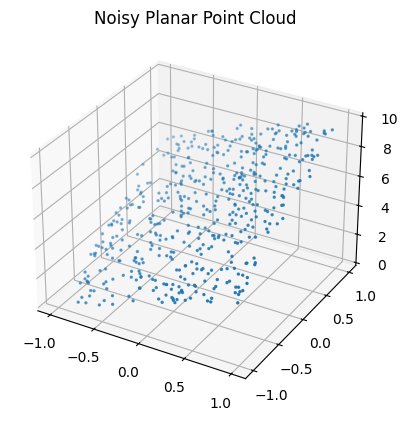

In [7]:
# Generate a noisy planar point cloud (planar space with eigen values)
num_points = 500
x = np.random.uniform(-1, 1, num_points)
y = np.random.uniform(-1, 1, num_points)
z = 2 * x + 3 * y + 5
points = np.vstack((x, y, z)).T
noise = np.random.normal(0, 0.01, points.shape)
noisy_points = points + noise
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')
ax.scatter(noisy_points[:, 0], noisy_points[:, 1], noisy_points[:, 2], s=2)
ax.set_title("Noisy Planar Point Cloud")
plt.show()

In [8]:
# The different methods of getting methods 
# 1. regular one :  knn 
from sklearn.neighbors import KNeighborsClassifier , NearestNeighbors
def GetNeighbors(X , n_neighbors=5) :
    knn = KNeighborsClassifier(n_neighbors=n_neighbors)
    knn.fit(X, np.zeros(X.shape[0])) 
    _, indices = knn.kneighbors(X, return_distance=True)
    neighbors = indices[:, 1:]
    return neighbors

# 2. using weighted knn 
def GetWeightedNeighbors(X , n_neighbors=5): 
    knn = KNeighborsClassifier(n_neighbors=n_neighbors, weights='distance')
    knn.fit(X, np.zeros(X.shape[0])) 
    _, indices = knn.kneighbors(X, return_distance=True)
    neighbors = indices[:, 1:]
    return neighbors
# 3. highest local planarity 
def highest_local_planarity_efficient(X, n_neighbors=5):
    nn = NearestNeighbors(n_neighbors=n_neighbors + 1)
    nn.fit(X)
    distances, indices = nn.kneighbors(X)

    min_curvature = float('inf')
    seed_index = -1

    for i in range(X.shape[0]):
        neighbor_indices = indices[i, 1:]
        neighbor_points = X[neighbor_indices]

        if neighbor_points.shape[0] < 3:
            continue

        covariance_matrix = compute_covariance(neighbor_points)
        eigenvalues, _ = compute_eigen_values_vectors(covariance_matrix)
        eigenvalues.sort()

        sum_eigen = np.sum(eigenvalues)
        if sum_eigen > 1e-9:
            curvature = eigenvalues[0] / sum_eigen
            if curvature < min_curvature:
                min_curvature = curvature
                seed_index = i

    if seed_index != -1:
        return  X[seed_index], X[indices[seed_index, 1:]] , seed_index , indices[seed_index, 1:]
    else:
        return None, None
# 4. using density 
def GetDensityBasedNeighbors(X, n_neighbors=5):
    nn = NearestNeighbors(n_neighbors=n_neighbors + 1)
    nn.fit(X)
    distances, indices = nn.kneighbors(X)

    density = np.zeros(X.shape[0])
    for i in range(X.shape[0]):
        density[i] = np.sum(np.exp(-distances[i, 1:] ** 2))
    densest_index = np.argmax(density)
    neighbor_indices = indices[densest_index, 1:]
    neighbors = X[neighbor_indices]
    return X[densest_index], neighbors , densest_index , neighbor_indices



In [9]:
# Get neighbors within the exploration part 
def make_axis_distance(axis):
    '''Create a distance function that measures distance along a specific axis.
    axis can be the following values 
    0 -> compute the distance per x axis 
    1 -> compute the distance per y axis 
    2 -> compute the distance per z axis 
    '''
    def distance_fn(x, y):
        return abs(x[axis] - y[axis])
    return distance_fn
def get_neighbors_within_exploration(X, axis , n_neighbors=5):
    per_axis_distance = make_axis_distance(axis)
    nn = NearestNeighbors(n_neighbors=n_neighbors + 1 , metric = per_axis_distance)
    nn.fit(X)
    distances, indices = nn.kneighbors(X)
    return distances , indices 


In [17]:
# Initial Algorithm implementation 
def initial_algorithm_implementation (X ,axis , n_neighbors ,  threshold_eigen_value=0.1 ): 
    # step 1 : get the seeds using one of the suggested methods above 
    seed, neighbors , seed_index , neighbor_index = GetDensityBasedNeighbors(X, n_neighbors=5)
    if seed is None:
        return 
    # step 2 : compute the covariance matrix of the seed and its neighbors
    covariance_matrix = compute_covariance(np.vstack((seed, neighbors)))
    # step 3 : compute the eigen values and vectors of the covariance matrix
    eig_val , _ = compute_eigen_values_vectors(covariance_matrix)
    # step 4 : check if the smallest eigen value is above the threshold
    eig_val.sort()
    initial_smallest_eig_value = eig_val[0]
    # step 5 : we will start to explore the neighbors of the seed 
    _, indices = get_neighbors_within_exploration(X, axis=axis, n_neighbors=n_neighbors)
    to_explore = list(neighbor_index)
    explored = set(neighbor_index)
    planar_plan = np.vstack((seed, neighbors))
    
    # step 6 : explore the neighbors until we reach a point where the smallest eigen value is below the threshold
    while to_explore : 
        idx = to_explore.pop()
        local_neighbors = indices[idx][1:]
        local_points = X[local_neighbors]
        local_covariance_matrix = compute_covariance(np.vstack((planar_plan , local_points)))
        eig_val , _ = compute_eigen_values_vectors(local_covariance_matrix)
        eig_val.sort()
        eig_val = eig_val[0]
        print ( eig_val , initial_smallest_eig_value )
        if eig_val > threshold_eigen_value : 
            return planar_plan 
        else : 
            planar_plan = np.vstack((planar_plan , local_points))
            for i in local_neighbors : 
                if i not in explored : 
                    to_explore.append(i)
                    explored.add(i)
    return planar_plan

    
    

In [18]:
print (initial_algorithm_implementation(noisy_points, axis=2, n_neighbors=5, threshold_eigen_value=0.1))

(-5.318805398931884e-15-1.4069878486664478e-15j) (-2.1327399113625687e-15-5.522606719229943e-16j)
(-8.389668253579875e-15+0j) (-2.1327399113625687e-15-5.522606719229943e-16j)
(-1.068676134760511e-14+0j) (-2.1327399113625687e-15-5.522606719229943e-16j)
(-2.7718980880737006e-14+0j) (-2.1327399113625687e-15-5.522606719229943e-16j)
(-7.260540517127224e-15-1.828582367925968e-15j) (-2.1327399113625687e-15-5.522606719229943e-16j)
(-1.2021229308993593e-14+0j) (-2.1327399113625687e-15-5.522606719229943e-16j)
(-1.1522117149763402e-14-6.337468340753541e-16j) (-2.1327399113625687e-15-5.522606719229943e-16j)
(-3.1942527951232404e-14+0j) (-2.1327399113625687e-15-5.522606719229943e-16j)
(-1.6098019837872277e-14+0j) (-2.1327399113625687e-15-5.522606719229943e-16j)
(-1.6707416335898214e-14+0j) (-2.1327399113625687e-15-5.522606719229943e-16j)
(-1.5540517653265937e-14+0j) (-2.1327399113625687e-15-5.522606719229943e-16j)
(-1.6338469145954026e-14+0j) (-2.1327399113625687e-15-5.522606719229943e-16j)
(-1.400

In [12]:
print (initial_algorithm_implementation(noisy_points, axis=0, n_neighbors=5, threshold_eigen_value=0.1))

(1.3663260342387247+0.35380222863296934j)
(0.5353594404680788+0.004676300468859475j)
(0.21718427164260046+0.0562386117263683j)
(0.46923121301669524+0.12150471025896602j)
(0.10696292899036751+0.027697432171807687j)
(0.17654976136849782+0.045716540175271055j)
(0.10088549615819001+0.026123716070006547j)
(0.08965521742407558-0.0881048269998303j)
[[ 0.23562437  0.41828046  6.68084354]
 [ 0.24626204  0.37582407  6.65809221]
 [ 0.2723631   0.40324529  6.71298003]
 [ 0.21753551  0.44319196  6.72467937]
 [ 0.16837137  0.43395524  6.64946786]
 [ 0.28424359  0.34451358  6.64037483]
 [ 0.28517018  0.54914964  7.20579569]
 [ 0.28735725  0.93633665  8.38825089]
 [ 0.28919018 -0.46838012  4.14645178]
 [ 0.2775727   0.30375496  6.44342024]
 [ 0.27737436 -0.96897504  2.67460891]
 [ 0.2775727   0.30375496  6.44342024]
 [ 0.27562014  0.72027372  7.73678169]
 [ 0.2723631   0.40324529  6.71298003]
 [ 0.2713174  -0.74481706  3.33599985]
 [ 0.28424359  0.34451358  6.64037483]
 [ 0.2723631   0.40324529  6.712

### Remark : 
&nbsp;&nbsp;&nbsp; for now the algorithm lacks in a lot of aspects it is worth the mention. The flaws are as follow: 
1. it is not iterative across all of the axis. 
2. it might miss planar plans by degree. <br>
<br>
Now, we will try to fix problem by problem and test against some edge cases **multiple edge cases**. <br>
Other than that, we will finish by testing against **existing methods**. <br>

## iterative across multiple axis : 
&nbsp;&nbsp;&nbsp; In this section , we will try to make the algorithm looks for planar plans across multiple axis (x-axis , y-axis , z-axis). and then we will test against some edge cases before moving towards other improvements. 

#### Remark : 
&nbsp;&nbsp;&nbsp; we should highlight a different problem in the implementation , where when we find the neighbors (2 or more). we should test individually the effect of one of them and accept the one that don't lead to the breaking of the verification rule by the threshold and the eigen value. 

In [ ]:
# we will try to also improve the seeding functions 
# in this section , we will try to implement the seeding functions in a more efficient way
#  1. highest local planarity 
def highest_local_planarity_efficient(X, n_neighbors=5):
    nn = NearestNeighbors(n_neighbors=n_neighbors + 1)
    nn.fit(X)
    distances, indices = nn.kneighbors(X)

    min_curvature = float('inf')
    seed_index = -1

    for i in range(X.shape[0]):
        neighbor_indices = indices[i, 1:]
        neighbor_points = X[neighbor_indices]

        if neighbor_points.shape[0] < 3:
            continue

        covariance_matrix = compute_covariance(neighbor_points)
        eigenvalues, _ = compute_eigen_values_vectors(covariance_matrix)
        eigenvalues.sort()

        sum_eigen = np.sum(eigenvalues)
        if sum_eigen > 1e-9:
            curvature = eigenvalues[0] / sum_eigen
            if curvature < min_curvature:
                min_curvature = curvature
                seed_index = i

    if seed_index != -1:
        return  X[seed_index], X[indices[seed_index, 1:]] , seed_index , indices[seed_index, 1:]
    else:
        return None, None
# 2. using density 
def GetDensityBasedNeighbors(X, n_neighbors=5):
    nn = NearestNeighbors(n_neighbors=n_neighbors + 1)
    nn.fit(X)
    distances, indices = nn.kneighbors(X)

    density = np.zeros(X.shape[0])
    for i in range(X.shape[0]):
        density[i] = np.sum(np.exp(-distances[i, 1:] ** 2))
    densest_index = np.argmax(density)
    neighbor_indices = indices[densest_index, 1:]
    neighbors = X[neighbor_indices]
    return X[densest_index], neighbors , densest_index , neighbor_indices



In [ ]:
# Initial Algorithm implementation 
def initial_algorithm_implementation (X ,axis , n_neighbors ,  threshold_eigen_value=0.1 ): 
    # step 1 : get the seeds using one of the suggested methods above 
    seed, neighbors , seed_index , neighbor_index = GetDensityBasedNeighbors(X, n_neighbors=5)
    if seed is None:
        return 
    # step 2 : compute the covariance matrix of the seed and its neighbors
    covariance_matrix = compute_covariance(np.vstack((seed, neighbors)))
    # step 3 : compute the eigen values and vectors of the covariance matrix
    eig_val , _ = compute_eigen_values_vectors(covariance_matrix)
    # step 4 : check if the smallest eigen value is above the threshold
    eig_val.sort()
    initial_smallest_eig_value = eig_val[0]
    # step 5 : we will start to explore the neighbors of the seed 
    _, indices = get_neighbors_within_exploration(X, axis=axis, n_neighbors=n_neighbors)
    to_explore = list(neighbor_index)
    explored = set(neighbor_index)
    planar_plan = np.vstack((seed, neighbors))
    
    # step 6 : explore the neighbors until we reach a point where the smallest eigen value is below the threshold
    while to_explore : 
        idx = to_explore.pop()
        local_neighbors = indices[idx][1:]
        local_points = X[local_neighbors]
        local_covariance_matrix = compute_covariance(np.vstack((planar_plan , local_points)))
        eig_val , _ = compute_eigen_values_vectors(local_covariance_matrix)
        eig_val.sort()
        eig_val = eig_val[0]
        print ( eig_val , initial_smallest_eig_value )
        if eig_val > threshold_eigen_value : 
            return planar_plan 
        else : 
            planar_plan = np.vstack((planar_plan , local_points))
            for i in local_neighbors : 
                if i not in explored : 
                    to_explore.append(i)
                    explored.add(i)
    return planar_plan

    
    